# 12 · LightGBM LambdaRank y optimización bayesiana

**Fase CRISP-DM:** 4. Modelado

**Objetivo:** entrenar el modelo principal y ajustar sus hiperparámetros con Optuna.

**Por qué LambdaRank:** la regresión logística aprende "¿lo va a pedir?" para cada platillo por separado. LambdaRank aprende directamente a **ordenar**: su pérdida está construida para mejorar NDCG y solo le importa que lo pedido quede **arriba** de lo no pedido **de la misma consulta**. Además, los árboles capturan interacciones (por ejemplo, el precio pesa distinto en una bebida que en un plato fuerte) que la logística no ve.

**Misma información, misma vara:** usa exactamente las features de la logística (`ranking/feature_sets.py`) y se compara en la misma validación (mes 10). La prueba sigue sin tocarse.

**Presupuesto de cómputo:** un entrenamiento completo tarda de 1.5 a 3 minutos en esta computadora. 100 intentos con 4 pliegues serían unas 13 horas. Se busca con **40 intentos** en un pliegue de origen móvil (entrena con el 30 % de las consultas de los meses 1 a 8 y valida en el mes 9), y lo mejor se verifica en el **mes 10, que Optuna nunca ve**, y con los **4 pliegues** completos (`config/models.yaml`).

**Entradas:** `data/Data_model/`. **Salidas:** `models/lgbm_para_ti.txt`, `models/lgbm_para_la_mesa.txt` y `models/lgbm_meta.json`.

> Este notebook solo narra el algoritmo. La lógica vive en `src/puzzle_recsys`.

## Configuración

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd

from puzzle_recsys.config import load_paths, load_simulation, load_yaml
from puzzle_recsys.evaluation.metrics import catalog_coverage, rank_metrics, summarize
from puzzle_recsys.ranking.feature_sets import FOR_TABLE, FOR_YOU
from puzzle_recsys.ranking.lgbm_ranker import fit_ranker, predict, to_lgbm
from puzzle_recsys.runtime import keep_awake
from puzzle_recsys.simulation.distributions import make_rng
from puzzle_recsys.splitting.temporal import rolling_origin_folds
from puzzle_recsys.tuning.optuna_search import run_study

keep_awake()  # la búsqueda dura ~45 min: que Windows no se suspenda
paths, sim, mcfg = load_paths(), load_simulation(), load_yaml("models")
ocfg, SEED, KS = mcfg["optuna"], sim.seed, tuple(mcfg["evaluation"]["k"])
ti = pd.read_parquet(paths.data_model / "para_ti.parquet")
ti = ti[ti["split"].isin(["train", "valid"])]
train, valid = ti[ti["split"] == "train"], ti[ti["split"] == "valid"]
base = pd.read_parquet(paths.data_model / "metricas_base_valid.parquet")
segmentos = valid.drop_duplicates("query_id").set_index("query_id")[["course", "tramo_historia", "primera_vez_restaurante"]]
dtr = to_lgbm(train, FOR_YOU)
dva = to_lgbm(valid, FOR_YOU, dtr.categories)
pd.Series({"features": dtr.X.shape[1], "filas train": len(dtr.y), "filas valid": len(dva.y)}, name="valor").to_frame().T

C:\Users\natal\Cundinamarca\Puzzle\Recomendador\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,features,filas train,filas valid
valor,33,2060781,235277


## 1. Modelo inicial

Hiperparámetros razonables, sin buscar: 31 hojas, tasa de aprendizaje 0.05 y al menos 50 filas por hoja. El número de árboles lo decide el **early stopping**: se agregan árboles hasta que el NDCG@3 en validación deja de mejorar durante 50 rondas.

In [2]:
inicial = {"num_leaves": 31, "learning_rate": 0.05, "min_child_samples": 50}
b0 = fit_ranker(dtr, dva, inicial, num_boost_round=ocfg["num_boost_round"],
                early_stopping_rounds=mcfg["lgbm_ranker"]["early_stopping_rounds"], seed=SEED)
s0 = predict(b0, valid, FOR_YOU, dtr.categories)
res = {"lgbm inicial": rank_metrics(valid.assign(score=s0), ks=KS, seed=SEED).join(segmentos, on="query_id")}
pd.Series({"árboles (early stopping)": b0.best_iteration,
           "NDCG@3 valid": summarize(res["lgbm inicial"])["ndcg@3"].iloc[0]}, name="valor").to_frame().T

,árboles (early stopping),NDCG@3 valid
valor,374.0,0.736533


## 2. Optuna (TPE)

**Optimización bayesiana:** en vez de probar todas las combinaciones (malla) o al azar, TPE usa los intentos anteriores. Separa los resultados en "buenos" y "malos", modela dónde caen los buenos y propone el siguiente intento donde es más probable mejorar.

**Espacio de búsqueda** (`config/models.yaml`): número de hojas (15 a 255, escala log), tasa de aprendizaje (0.01 a 0.2, log), filas mínimas por hoja (10 a 200, log), fracción de features por árbol (0.5 a 1) y regularización L2 (0.001 a 10, log).

**Pliegue de búsqueda:** entrena con el 30 % de las consultas de los meses 1 a 8 y valida en el mes 9. Como el early stopping y la puntuación usan el mismo mes 9, el valor de Optuna es algo **optimista**; por eso el ganador se juzga en el mes 10.

In [3]:
meses_q = train.drop_duplicates("query_id").set_index("query_id")["mes"]
lo, hi = ocfg["fit_months"]
fit_q = meses_q[meses_q.between(lo, hi)].index.to_numpy()
fit_q = make_rng(SEED, "optuna_queries").choice(fit_q, int(ocfg["query_share"] * len(fit_q)), replace=False)
fit_df = train[train["query_id"].isin(set(fit_q))]
eval_df = train[train["mes"] == ocfg["eval_month"]]
dfit = to_lgbm(fit_df, FOR_YOU)
deval = to_lgbm(eval_df, FOR_YOU, dfit.categories)

def objetivo(params):
    b = fit_ranker(dfit, deval, params, num_boost_round=ocfg["num_boost_round"],
                   early_stopping_rounds=mcfg["lgbm_ranker"]["early_stopping_rounds"], seed=SEED)
    return b.best_score["valid_0"]["ndcg@3"]

estudio = run_study(objetivo, ocfg["search_space"], n_trials=ocfg["n_trials"], seed=SEED)
historia = estudio.trials_dataframe()[["number", "value", *[f"params_{p}" for p in ocfg["search_space"]]]]
display(pd.Series({"consultas de ajuste": len(fit_q), "consultas de evaluación (mes 9)": eval_df["query_id"].nunique(),
                   "mejor NDCG@3 (mes 9)": estudio.best_value}, name="valor").to_frame().T)
pd.Series(estudio.best_params, name="mejores hiperparámetros").to_frame()

,consultas de ajuste,consultas de evaluación (mes 9),mejor NDCG@3 (mes 9)
valor,96457.0,39945.0,0.737534


,mejores hiperparámetros
num_leaves,114.000000
learning_rate,0.027033
min_child_samples,157.000000
feature_fraction,0.599286
lambda_l2,3.942170


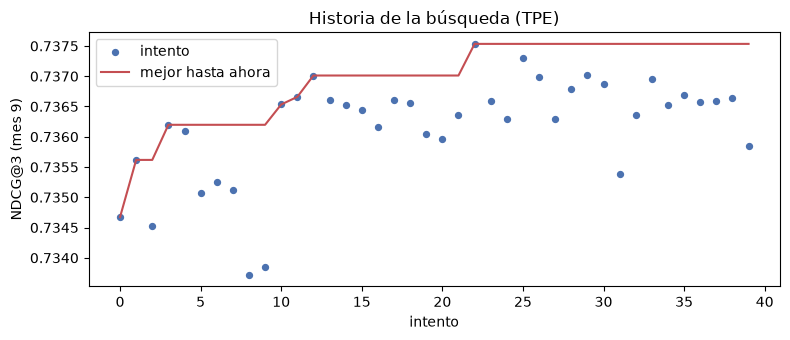

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.scatter(historia["number"], historia["value"], s=18, color="#4C72B0", label="intento")
ax.plot(historia["number"], historia["value"].cummax(), color="#C44E52", label="mejor hasta ahora")
ax.set_xlabel("intento"); ax.set_ylabel("NDCG@3 (mes 9)"); ax.set_title("Historia de la búsqueda (TPE)"); ax.legend()
fig.tight_layout(); fig.savefig(paths.figures / "12_historia_optuna.png", dpi=150)

## 3. Importancia de hiperparámetros

¿Cuáles hiperparámetros movieron el resultado? Optuna lo estima con **fANOVA**: ajusta un bosque que predice el NDCG a partir de los hiperparámetros y descompone su varianza. Un hiperparámetro con importancia baja da casi lo mismo en cualquier valor del rango.

,importancia
min_child_samples,0.402
learning_rate,0.351
feature_fraction,0.117
num_leaves,0.069
lambda_l2,0.062


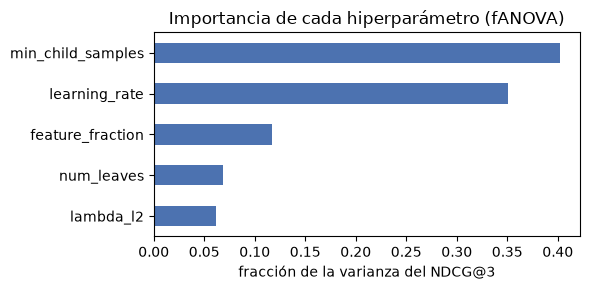

In [5]:
imp = pd.Series(optuna.importance.get_param_importances(estudio, evaluator=optuna.importance.FanovaImportanceEvaluator(seed=SEED)))
fig, ax = plt.subplots(figsize=(6, 3))
imp.sort_values().plot.barh(ax=ax, color="#4C72B0")
ax.set_title("Importancia de cada hiperparámetro (fANOVA)"); ax.set_xlabel("fracción de la varianza del NDCG@3")
fig.tight_layout(); fig.savefig(paths.figures / "12_importancia_hiperparametros.png", dpi=150)
imp.round(3).rename("importancia").to_frame()

## 4. Modelo final "para ti"

Se reentrena con los mejores hiperparámetros y **todo** el entrenamiento (meses 1 a 9), con early stopping en el mes 10.

In [6]:
best = dict(estudio.best_params)
bf = fit_ranker(dtr, dva, best, num_boost_round=ocfg["num_boost_round"],
                early_stopping_rounds=mcfg["lgbm_ranker"]["early_stopping_rounds"], seed=SEED)
sf = predict(bf, valid, FOR_YOU, dtr.categories)
res["lgbm ajustado"] = rank_metrics(valid.assign(score=sf), ks=KS, seed=SEED).join(segmentos, on="query_id")
todos = pd.concat([base, *[r.assign(modelo=k) for k, r in res.items()]], ignore_index=True)
orden = ["azar", "popularidad", "contenido", "logística", "lgbm inicial", "lgbm ajustado"]
tabla = summarize(todos, by="modelo").set_index("modelo").loc[orden]
tabla["cobertura@3"] = np.nan
tabla.loc["lgbm inicial", "cobertura@3"] = catalog_coverage(valid.assign(score=s0), k=3, seed=SEED)
tabla.loc["lgbm ajustado", "cobertura@3"] = catalog_coverage(valid.assign(score=sf), k=3, seed=SEED)
display(pd.Series({"árboles (early stopping)": bf.best_iteration}, name="valor").to_frame().T)
tabla.round(4)

,árboles (early stopping)
valor,425


,consultas,ndcg@3,hit@3,recall@3,map@3,ndcg@5,hit@5,recall@5,map@5,cobertura@3
modelo,,,,,,,,,,
azar,40056,0.4622,0.6031,0.6031,0.4137,0.5460,0.8067,0.8067,0.4602,NaN
popularidad,40056,0.6565,0.7938,0.7938,0.6090,0.7066,0.9150,0.9150,0.6370,NaN
contenido,40056,0.6492,0.7927,0.7927,0.5997,0.7026,0.9217,0.9217,0.6295,NaN
logística,40056,0.7027,0.8396,0.8396,0.6553,0.7453,0.9424,0.9424,0.6791,NaN
lgbm inicial,40056,0.7365,0.8654,0.8654,0.6919,0.7736,0.9546,0.9546,0.7126,0.7432
lgbm ajustado,40056,0.7371,0.8659,0.8659,0.6925,0.7742,0.9555,0.9555,0.7132,0.7410


In [7]:
for seg in ["course", "tramo_historia", "primera_vez_restaurante"]:
    display(summarize(todos, by=["modelo", seg]).pivot(index=seg, columns="modelo", values="ndcg@3")[orden].round(3))

modelo,azar,popularidad,contenido,logística,lgbm inicial,lgbm ajustado
course,,,,,,
DESSERT,0.706,0.818,0.796,0.836,0.861,0.862
DRINK,0.432,0.660,0.589,0.686,0.729,0.729
MAIN,0.295,0.531,0.579,0.613,0.650,0.650
SIDE,0.909,0.938,0.925,0.943,0.949,0.949
STARTER,0.752,0.835,0.836,0.858,0.872,0.874


modelo,azar,popularidad,contenido,logística,lgbm inicial,lgbm ajustado
tramo_historia,,,,,,
1-5,0.496,0.639,0.559,0.638,0.705,0.688
6-20,0.477,0.666,0.628,0.699,0.737,0.735
21+,0.458,0.654,0.655,0.704,0.737,0.738


modelo,azar,popularidad,contenido,logística,lgbm inicial,lgbm ajustado
primera_vez_restaurante,,,,,,
False,0.458,0.655,0.662,0.706,0.739,0.739
True,0.472,0.661,0.618,0.696,0.732,0.732


### Estabilidad en el tiempo: validación cruzada por origen móvil

Con los hiperparámetros elegidos se entrena 4 veces: con los meses 1 a 5 se valida en el 6, con 1 a 6 en el 7, y así hasta el 9. Si el modelo solo funcionara en el mes 10 por suerte, se vería aquí. El número de árboles queda fijo (el del modelo final) para no usar cada mes de validación para decidir cuándo parar.

In [8]:
import lightgbm as lgb

cv = []
for k, (fit_mask, val_mask) in enumerate(rolling_origin_folds(meses_q, train_end=mcfg["split"]["train"][1],
                                                                n_folds=mcfg["split"]["cv_rolling_folds"])):
    f_df = train[train["query_id"].isin(set(meses_q.index[fit_mask.to_numpy()]))]
    v_df = train[train["query_id"].isin(set(meses_q.index[val_mask.to_numpy()]))]
    df_ = to_lgbm(f_df, FOR_YOU)
    booster = lgb.train({"objective": "lambdarank", "metric": "ndcg", "eval_at": [3], "seed": SEED, "deterministic": True,
                         "force_row_wise": True, "verbose": -1, **best},
                        lgb.Dataset(df_.X, df_.y, group=df_.group), num_boost_round=bf.best_iteration)
    scores = predict(booster, v_df, FOR_YOU, df_.categories)
    cv.append({"pliegue": k + 1, "valida en el mes": int(v_df["mes"].iloc[0]),
               "NDCG@3": summarize(rank_metrics(v_df.assign(score=scores), ks=(3,), seed=SEED))["ndcg@3"].iloc[0]})
cv = pd.DataFrame(cv)
display(cv.round(4))
pd.Series({"media": cv["NDCG@3"].mean(), "desviación estándar": cv["NDCG@3"].std()}, name="NDCG@3 (4 pliegues)").round(4).to_frame().T

,pliegue,valida en el mes,NDCG@3
0,1,6,0.7384
1,2,7,0.7384
2,3,8,0.7420
3,4,9,0.7398


,media,desviación estándar
NDCG@3 (4 pliegues),0.7397,0.0017


,ganancia
canonical_pred,0.292
share_restaurante,0.273
share_proteina,0.081
log_veces_pidio_canonico,0.071
afinidad_cocina_platillo,0.038
share_global_canonico,0.030
franja,0.024
log_dias_en_menu,0.021
log_pedidos_previos_platillo,0.020
log_visitas_previas,0.016


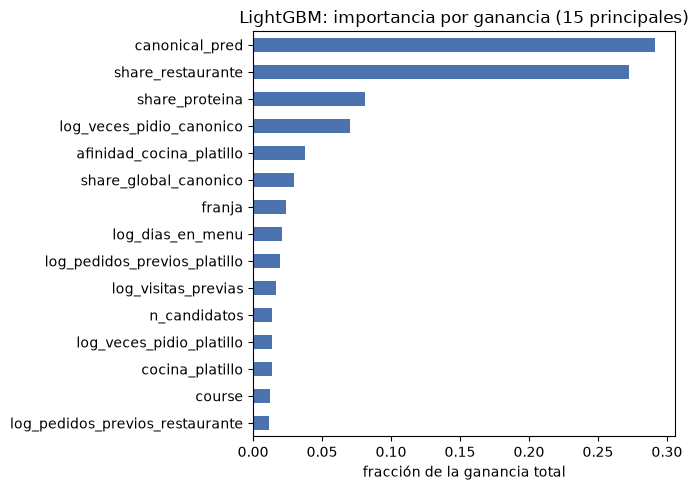

In [9]:
gain = pd.Series(bf.feature_importance(importance_type="gain"), index=bf.feature_name())
gain = (gain / gain.sum()).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(7, 5))
gain.head(15).iloc[::-1].plot.barh(ax=ax, color="#4C72B0")
ax.set_title("LightGBM: importancia por ganancia (15 principales)"); ax.set_xlabel("fracción de la ganancia total")
fig.tight_layout(); fig.savefig(paths.figures / "12_importancia_features.png", dpi=150)
gain.head(15).round(3).rename("ganancia").to_frame()

## 5. Modelo "para la mesa"

Mismo procedimiento con `FOR_TABLE`. Como el conjunto es chico (unas 26,000 mesas de entrenamiento), la búsqueda es rápida: 40 intentos entrenando con los meses 1 a 8 y validando en el 9 (todas las mesas, sin submuestra). La métrica principal es **@1**, porque la mediana es de 2 candidatos por mesa.

In [10]:
mesa = pd.read_parquet(paths.data_model / "para_la_mesa.parquet")
mesa = mesa[mesa["split"].isin(["train", "valid"])]
mtr, mva = mesa[mesa["split"] == "train"], mesa[mesa["split"] == "valid"]
mfit, meval = mtr[mtr["mes"].between(lo, hi)], mtr[mtr["mes"] == ocfg["eval_month"]]
dmfit = to_lgbm(mfit, FOR_TABLE)
dmeval = to_lgbm(meval, FOR_TABLE, dmfit.categories)

def objetivo_mesa(params):
    b = fit_ranker(dmfit, dmeval, params, num_boost_round=ocfg["num_boost_round"],
                   early_stopping_rounds=mcfg["lgbm_ranker"]["early_stopping_rounds"], seed=SEED, eval_at=1)
    return b.best_score["valid_0"]["ndcg@1"]

estudio_mesa = run_study(objetivo_mesa, ocfg["search_space"], n_trials=ocfg["n_trials"], seed=SEED)
dmtr = to_lgbm(mtr, FOR_TABLE)
dmva = to_lgbm(mva, FOR_TABLE, dmtr.categories)
bm = fit_ranker(dmtr, dmva, estudio_mesa.best_params, num_boost_round=ocfg["num_boost_round"],
                early_stopping_rounds=mcfg["lgbm_ranker"]["early_stopping_rounds"], seed=SEED, eval_at=1)
sm = predict(bm, mva, FOR_TABLE, dmtr.categories)

import joblib
from puzzle_recsys.ranking.baselines import random_score
from puzzle_recsys.ranking.feature_sets import model_frame

log_mesa = joblib.load(paths.models / "logistica_para_la_mesa.joblib")
Mva = model_frame(mva, FOR_TABLE)
scores_mesa = {"azar": random_score(mva, seed=SEED), "popularidad de compartir": mva["tasa_compartido_canonico"],
               "logística": log_mesa.predict_proba(Mva[list(FOR_TABLE.columns)])[:, 1], "lgbm ajustado": sm}
res_mesa = pd.concat([rank_metrics(mva.assign(score=s), ks=(1, 3), seed=SEED).assign(modelo=k) for k, s in scores_mesa.items()])
display(pd.Series({"árboles (early stopping)": bm.best_iteration}, name="valor").to_frame().T)
summarize(res_mesa, by="modelo").set_index("modelo").loc[list(scores_mesa)][["consultas", "ndcg@1", "hit@1", "ndcg@3", "map@3"]].round(3)

,árboles (early stopping)
valor,25


,consultas,ndcg@1,hit@1,ndcg@3,map@3
modelo,,,,,
azar,2866,0.612,0.612,0.816,0.769
popularidad de compartir,2866,0.740,0.740,0.878,0.847
logística,2866,0.833,0.833,0.926,0.905
lgbm ajustado,2866,0.851,0.851,0.930,0.913


## 6. Guardado

In [11]:
paths.models.mkdir(parents=True, exist_ok=True)
bf.save_model(str(paths.models / "lgbm_para_ti.txt"), num_iteration=bf.best_iteration)
bm.save_model(str(paths.models / "lgbm_para_la_mesa.txt"), num_iteration=bm.best_iteration)
meta = {"para_ti": {"params": best, "best_iteration": bf.best_iteration, "categories": dtr.categories},
        "para_la_mesa": {"params": estudio_mesa.best_params, "best_iteration": bm.best_iteration, "categories": dmtr.categories}}
(paths.models / "lgbm_meta.json").write_text(json.dumps(meta, ensure_ascii=False, indent=1), encoding="utf-8")
todos[todos["modelo"].str.startswith("lgbm")].to_parquet(paths.data_model / "metricas_lgbm_valid.parquet", index=False)
historia.to_csv(paths.models / "optuna_historia_para_ti.csv", index=False)
"modelos, metadatos e historia de Optuna guardados en models/"

'modelos, metadatos e historia de Optuna guardados en models/'

## Conclusiones

### 1. LightGBM le gana a todo en validación ("para ti")

| Modelo | NDCG@3 | HitRate@3 | MAP@3 |
|---|---|---|---|
| Popularidad | 0.656 | 0.794 | 0.609 |
| Regresión logística | 0.703 | 0.840 | 0.655 |
| LightGBM inicial | 0.737 | 0.865 | 0.692 |
| **LightGBM ajustado** | **0.737** | **0.866** | **0.693** |

- **+0.034 de NDCG@3 sobre la logística** y +0.081 sobre la popularidad. Lo pedido queda en el top 3 en el **87 %** de las consultas. Que la mejora sea real (y no ruido) se prueba en el notebook 13.
- **Mejora en todos los tipos de plato**, sobre todo donde más importa: plato fuerte (0.613 → 0.650) y bebida (0.686 → 0.729).
- **Primera vez en el restaurante:** 0.732 contra 0.739 cuando ya lo conocía. Lo aprendido se **transfiere** entre restaurantes, que era el objetivo de usar el canónico.

### 2. Optuna: el valor por defecto ya era casi el óptimo

- 40 intentos de TPE subieron el NDCG@3 de validación solo de **0.7365 a 0.7371**. La diferencia es **despreciable**, muy por debajo del mínimo relevante (0.01).
- **Lectura honesta:** con 2 millones de filas y señales fuertes, LightGBM es poco sensible a sus hiperparámetros. Los más influyentes fueron las filas mínimas por hoja (40 % de la varianza) y la tasa de aprendizaje (35 %). Los ganadores (114 hojas, al menos 157 filas por hoja, 60 % de las features por árbol) apuntan a **más regularización**: árboles grandes, pero con hojas que necesitan mucha evidencia.
- Se usa el ajustado porque fue elegido sin mirar el mes 10, pero en producción la configuración inicial serviría igual.
- **Ojo:** con 1-5 visitas previas el ajustado rinde menos que el inicial (0.688 contra 0.705). Son solo 95 consultas (0.2 %), así que la diferencia es mayormente ruido, pero confirma que **el segmento de poca historia necesita su propia evaluación** (contrafactual del notebook 13).

### 3. Estable en el tiempo

En la validación cruzada por origen móvil, el NDCG@3 es de **0.738 a 0.742** en los meses 6 a 9 (desviación estándar de **0.002**). El modelo no depende de un mes con suerte y no se degrada mes a mes.

### 4. Qué usa el modelo (importancia por ganancia)

1. **Qué platillo es** (canónico, 29 %) y **qué tan popular es en ese restaurante** (27 %): la mitad de la decisión.
2. **La historia de la persona:** proteína que suele pedir (8 %), si ya pidió ese canónico (7 %) y su afinidad por la cocina (4 %).
3. **Contexto:** la franja (2 %), que viene del efecto de contexto agregado en el notebook 07.

Es la ganancia de los árboles, que favorece variables con muchas categorías como el canónico. La explicación fina, por platillo y con dirección del efecto, se hace con SHAP en el notebook 14 y se compara contra la verdad oculta.

### 5. "Para la mesa"

| Modelo | Hit@1 |
|---|---|
| Azar | 0.612 |
| Popularidad de compartir | 0.740 |
| Logística | 0.833 |
| **LightGBM** | **0.851** |

LightGBM también gana (+0.018 sobre la logística), aunque con un modelo muy chico (25 árboles): son solo 26,000 mesas de entrenamiento, con 2 candidatos cada una.

**Pasa al notebook 13:** sobreajuste, pruebas pareadas por comensal, potencia y arranque en frío.
